In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import arviz as az
import bambi as bmb
from scipy.stats import binom

In [2]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

HOOFDKLEUR = '#007044'
NACHT = KLEUR_NACHT


def nl(getal):
    return f"{getal:,}".replace(",", ".")

PALET = ['#0067B9', '#FF9527', '#E100A3', '#9569BE', '#007044', '#00859B', '#CC982F',
         '#F275D4', '#59C0D1', '#4A5B84', '#FFD200', '#1A915E', '#27376B']

plt.rcParams.update({
    'font.family': 'Libertinus Serif',
    'font.size': CORPS,
    
    'axes.titlesize': CORPS,
    'axes.labelsize': CORPS,
    'xtick.labelsize': CORPS,
    'ytick.labelsize': CORPS,
    'legend.fontsize': CORPS,
    
    'figure.figsize': (TEKSTBREEDTE, TEKSTBREEDTE * 0.66),
})

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [3]:
map_macro = Path("../../data/algemeen/gebeurtenisdata_macro")
excel_files = sorted([f for f in map_macro.glob("*.xlsx")])

print(len(excel_files))

dataframes = []
for file in excel_files:
    try:
        df = pd.read_excel(file)
        dataframes.append(df)
    except Exception as e:
        print(file.name)

df_macro = pd.concat(dataframes, ignore_index=True)


198
._MA#30830.xlsx


In [4]:
df_geluid = pd.read_excel("../../data/H8/geluidsoverlast_macro.xlsx")

In [5]:
df_macro = df_macro[df_macro['year'] <= 1939].copy()
df_geluid = df_geluid[df_geluid['year'] <= 1939].copy()

In [6]:
merge_keys = ["archive_file", "Incident Number"]

geluid_incidents = set(
    zip(df_geluid["archive_file"], df_geluid["Incident Number"])
)


In [7]:
df_macro = df_macro.copy()

df_macro["is_geluid"] = [
    int((archive_file, incident_number) in geluid_incidents)
    for archive_file, incident_number in zip(
        df_macro["archive_file"],
        df_macro["Incident Number"]
    )
]

df_unique = df_macro.drop_duplicates(
    subset=merge_keys
).copy()

In [8]:
df_valid = df_unique[
    df_unique["astro"].notna() &
    (df_unique["astro"] != "unknown")
].copy()

In [9]:
totaal_uniek = len(df_unique)
met_dag_nacht = len(df_valid)
zonder_dag_nacht = totaal_uniek - met_dag_nacht

print(f"Unieke gebeurtenissen: {totaal_uniek:,}")
print(f"Met dag/nacht-informatie: {met_dag_nacht:,}")
print(f"Zonder dag/nacht-informatie: {zonder_dag_nacht:,}")
print(f"Geluidsoverlast in geldige data: {df_valid['is_geluid'].sum():,}")

print("\nAstro:")
print(df_valid["astro"].value_counts())

Unieke gebeurtenissen: 157,665
Met dag/nacht-informatie: 79,927
Zonder dag/nacht-informatie: 77,738
Geluidsoverlast in geldige data: 2,191

Astro:
astro
dag                  48254
nacht                28638
avondschemering       2402
ochtendschemering      633
Name: count, dtype: int64


In [10]:
NACHTCATS = ["nacht", "avondschemering", "ochtendschemering"]

df_nacht = df_valid[df_valid["astro"].isin(NACHTCATS)].copy()

N = len(df_nacht)
n_geluid = df_nacht["is_geluid"].sum()

print(f"Nachtelijke gebeurtenissen: {N:,}")
print(f"Geluidsoverlast: {n_geluid:,}")
print(f"Aandeel geluidsoverlast: {n_geluid / N * 100:.2f}%")

Nachtelijke gebeurtenissen: 31,673
Geluidsoverlast: 1,705
Aandeel geluidsoverlast: 5.38%


In [11]:
d_jaar = (
    df_nacht
    .groupby("year")
    .agg(
        k=("is_geluid", "sum"),   # geluidsoverlast
        n=("is_geluid", "size")   # alle nachtelijke gebeurtenissen
    )
    .reset_index()
)

d_jaar["aandeel"] = d_jaar["k"] / d_jaar["n"] * 100

print(d_jaar.to_string(index=False))

print("\nAantal jaren:", len(d_jaar))
print("Totaal N:", d_jaar["n"].sum())
print("Totaal geluid:", d_jaar["k"].sum())
print("Min. gebeurtenissen per jaar:", d_jaar["n"].min())
print("Max. gebeurtenissen per jaar:", d_jaar["n"].max())

 year  k    n   aandeel
 1876 30  277 10.830325
 1877 18  750  2.400000
 1878 40  598  6.688963
 1879 12  380  3.157895
 1880 52  608  8.552632
 1881 23  155 14.838710
 1882 74  694 10.662824
 1883 25  449  5.567929
 1884 30  406  7.389163
 1885 21  420  5.000000
 1886 35  772  4.533679
 1887 44  870  5.057471
 1888 23  363  6.336088
 1889 51  809  6.304079
 1890 45  960  4.687500
 1891 80  837  9.557945
 1892 38  439  8.656036
 1893 37  252 14.682540
 1894  5  189  2.645503
 1895  1  165  0.606061
 1896 28  361  7.756233
 1899 27  306  8.823529
 1900 40  353 11.331445
 1901  0   77  0.000000
 1902 26  548  4.744526
 1903  9  221  4.072398
 1904  6  193  3.108808
 1905 12  306  3.921569
 1907  0  105  0.000000
 1908 18  444  4.054054
 1909 18  278  6.474820
 1910 17  307  5.537459
 1911 20  288  6.944444
 1912 35  555  6.306306
 1913 68 1069  6.361085
 1914 29  268 10.820896
 1919 10  264  3.787879
 1920 28  557  5.026930
 1921 67  825  8.121212
 1922 45  774  5.813953
 1923 41  657  6

In [12]:
print(
    d_jaar.sort_values("n")
    [["year", "k", "n", "aandeel"]]
    .head(10)
)

    year   k    n    aandeel
23  1901   0   77   0.000000
28  1907   0  105   0.000000
5   1881  23  155  14.838710
19  1895   1  165   0.606061
18  1894   5  189   2.645503
26  1904   6  193   3.108808
25  1903   9  221   4.072398
17  1893  37  252  14.682540
36  1919  10  264   3.787879
35  1914  29  268  10.820896


In [13]:
jaar_gem = d_jaar["year"].mean()

d_jaar["year_c"] = d_jaar["year"] - jaar_gem

print(f"Gemiddeld jaar: {jaar_gem:.2f}")
print(d_jaar[["year", "year_c", "k", "n", "aandeel"]].head())

Gemiddeld jaar: 1907.25
   year     year_c   k    n    aandeel
0  1876 -31.245614  30  277  10.830325
1  1877 -30.245614  18  750   2.400000
2  1878 -29.245614  40  598   6.688963
3  1879 -28.245614  12  380   3.157895
4  1880 -27.245614  52  608   8.552632


In [14]:
jaar_gem = d_jaar["year"].mean()
d_jaar["year_c"] = d_jaar["year"] - jaar_gem

In [15]:
priors = {
    "hsgp(year_c, m=25, c=1.5)": {
        "sigma": bmb.Prior("Exponential", lam=1),
        "ell": bmb.Prior("InverseGamma", alpha=4, beta=40),
    }
}

In [16]:
model_spline = bmb.Model(
    "p(k, n) ~ bs(year_c, df=4)",
    d_jaar,
    family="beta_binomial"
)

model_spline

       Formula: p(k, n) ~ bs(year_c, df=4)
        Family: beta_binomial
          Link: mu = logit
  Observations: 57
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 0.0, sigma: 5.7663)
            bs(year_c, df=4) ~ Normal(mu: [0. 0. 0. 0.], sigma: [11.0888 14.2381 11.3201  9.6241])
        
        Auxiliary parameters
            kappa ~ HalfCauchy(beta: 1.0)

In [17]:
idata_spline = model_spline.fit(
    draws=2000,
    tune=2000,
    chains=4,
    random_seed=42,
    target_accept=0.95
)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [kappa, Intercept, bs(year_c, df=4)]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 7 seconds.


In [18]:
print("Divergences:",
      idata_spline.sample_stats["diverging"].sum().item())

az.summary(idata_spline)

Divergences: 0


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
kappa,101.210,28.669,53.693,156.074,0.373,0.270,6071.0,5331.0,1.0
Intercept,-2.715,0.253,-3.194,-2.237,0.003,0.002,5456.0,5220.0,1.0
"bs(year_c, df=4)[0]",0.366,0.532,-0.561,1.398,0.008,0.006,4848.0,5009.0,1.0
"bs(year_c, df=4)[1]",-0.708,0.491,-1.622,0.222,0.007,0.005,5517.0,4663.0,1.0
"bs(year_c, df=4)[2]",0.420,0.503,-0.514,1.366,0.007,0.006,4820.0,4913.0,1.0
"bs(year_c, df=4)[3]",-1.055,0.404,-1.820,-0.306,0.005,0.004,6255.0,5413.0,1.0


In [19]:
alle_jaren = np.arange(1876, 1940)

nieuw = pd.DataFrame({
    "year": alle_jaren,
    "year_c": alle_jaren - jaar_gem
})

model_spline.predict(
    idata_spline,
    data=nieuw,
    kind="response_params"
)

p = idata_spline.posterior["mu"] * 100

gem = p.mean(("chain", "draw")).values
h94 = az.hdi(p, hdi_prob=0.94)["mu"].values
h50 = az.hdi(p, hdi_prob=0.50)["mu"].values

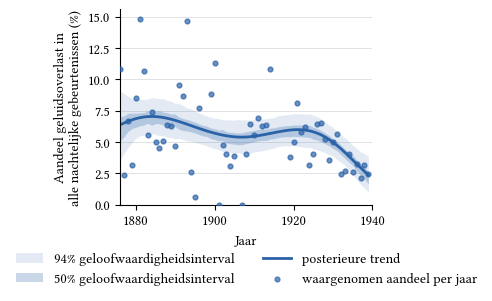

In [20]:
fig, ax = plt.subplots()

ax.fill_between(
    alle_jaren, h94[:, 0], h94[:, 1],
    color=NACHT, alpha=0.13, lw=0,
    label="94% geloofwaardigheidsinterval"
)

ax.fill_between(
    alle_jaren, h50[:, 0], h50[:, 1],
    color=NACHT, alpha=0.25, lw=0,
    label="50% geloofwaardigheidsinterval"
)

ax.plot(
    alle_jaren, gem,
    color=NACHT, lw=2,
    label="posterieure trend"
)

ax.scatter(
    d_jaar["year"],
    d_jaar["aandeel"],
    s=12, color=NACHT,
    alpha=0.7, zorder=3,
    label="waargenomen aandeel per jaar"
)

ax.set_xlim(1876, 1940)
ax.set_ylim(bottom=0)

ax.set_xlabel("Jaar")
ax.set_ylabel(
    "Aandeel geluidsoverlast in\n"
    "alle nachtelijke gebeurtenissen (%)"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False
)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y")

plt.tight_layout()
plt.subplots_adjust(bottom=0.25)

#fig.savefig(
#    "../../fig/H8/4.7_aandeel_geluidsoverlast_stadsbreed_spline.png",
#    dpi=300,
#    bbox_inches="tight"
#)

plt.show()

In [21]:
# p bevat de posterior voorspelde kansen voor 1876–1939
# dimensies: chain × draw × jaar

p_prob = idata_spline.posterior["mu"]

# Jaar-op-jaar verandering in procentpunten
delta = p_prob.diff(dim="__obs__") * 100

# Samenvatten
delta_mean = delta.mean(("chain", "draw")).values
delta_h94 = az.hdi(delta, hdi_prob=0.94)["mu"].values

# De verandering van jaar t naar t+1 koppelen aan t+1
jaren_delta = alle_jaren[1:]

d_delta = pd.DataFrame({
    "year": jaren_delta,
    "verandering": delta_mean,
    "onder": delta_h94[:, 0],
    "boven": delta_h94[:, 1]
})

d_delta.head()

,year,verandering,onder,boven
0,1877,0.148444,-0.361190,0.582974
1,1878,0.134015,-0.327642,0.568045
2,1879,0.116798,-0.304368,0.530096
3,1880,0.097416,-0.281521,0.485771
4,1881,0.076522,-0.255575,0.445198


In [22]:
dalend = d_delta[d_delta["boven"] < 0]
stijgend = d_delta[d_delta["onder"] > 0]

print("Daling met 94% geloofwaardigheidsinterval volledig onder nul:")
print(dalend.to_string(index=False))

print("\nStijging met 94% geloofwaardigheidsinterval volledig boven nul:")
print(stijgend.to_string(index=False))

Daling met 94% geloofwaardigheidsinterval volledig onder nul:
 year  verandering     onder     boven
 1927    -0.137218 -0.279736 -0.013368
 1928    -0.166471 -0.316528 -0.024739
 1929    -0.195158 -0.358758 -0.037125
 1930    -0.222394 -0.400726 -0.043714
 1931    -0.247276 -0.435657 -0.050183
 1932    -0.268932 -0.472733 -0.064355
 1933    -0.286577 -0.493748 -0.068837
 1934    -0.299566 -0.512879 -0.080904
 1935    -0.307447 -0.522123 -0.096529
 1936    -0.310002 -0.511468 -0.105401
 1937    -0.307261 -0.492077 -0.111847
 1938    -0.299510 -0.466248 -0.114593
 1939    -0.287263 -0.437521 -0.117462

Stijging met 94% geloofwaardigheidsinterval volledig boven nul:
Empty DataFrame
Columns: [year, verandering, onder, boven]
Index: []


In [23]:
comp = (df_nacht.groupby(["year", "district"])
        .size().unstack(fill_value=0))

print((comp.div(comp.sum(axis=1), axis=0) * 100).round(0).to_string())

district     1      3      5      6      7     8     9     11
year                                                         
1876        0.0    0.0  100.0    0.0    0.0   0.0   0.0   0.0
1877        0.0  100.0    0.0    0.0    0.0   0.0   0.0   0.0
1878        0.0   57.0   43.0    0.0    0.0   0.0   0.0   0.0
1879      100.0    0.0    0.0    0.0    0.0   0.0   0.0   0.0
1880        0.0  100.0    0.0    0.0    0.0   0.0   0.0   0.0
1881        0.0  100.0    0.0    0.0    0.0   0.0   0.0   0.0
1882       43.0   57.0    0.0    0.0    0.0   0.0   0.0   0.0
1883        0.0  100.0    0.0    0.0    0.0   0.0   0.0   0.0
1884        0.0  100.0    0.0    0.0    0.0   0.0   0.0   0.0
1885        0.0  100.0    0.0    0.0    0.0   0.0   0.0   0.0
1886        0.0  100.0    0.0    0.0    0.0   0.0   0.0   0.0
1887        0.0  100.0    0.0    0.0    0.0   0.0   0.0   0.0
1888        0.0  100.0    0.0    0.0    0.0   0.0   0.0   0.0
1889        0.0  100.0    0.0    0.0    0.0   0.0   0.0   0.0
1890    

In [24]:
per_wijk = (df_nacht.groupby("district")
            .agg(k=("is_geluid", "sum"), n=("is_geluid", "size")))
per_wijk["aandeel"] = per_wijk["k"] / per_wijk["n"] * 100
print(per_wijk.round(1).to_string())

            k      n  aandeel
district                     
1         255   2748      9.3
3         738  15069      4.9
5          86    993      8.7
6         110   3988      2.8
7         142   4059      3.5
8          18    409      4.4
9          66   1129      5.8
11        290   3278      8.8


In [25]:
NACHTCATS = ["nacht", "avondschemering", "ochtendschemering"]
WOI = (1914, 1918)

d = df_unique[
    df_unique["astro"].isin(NACHTCATS)
    & df_unique["year"].between(1876, 1939)
    & ~df_unique["year"].between(*WOI)
    & df_unique["district"].notna()
].copy()

d = d[~d["district"].isin([8, 9, 10])]
d["district"] = d["district"].replace({7: 6, 11: 5})

agg = (d.groupby(["district", "year"])
       .agg(k=("is_geluid", "sum"), n=("is_geluid", "size"))
       .reset_index())

agg["jaar_c"] = (agg["year"] - 1900) / 10
agg["district"] = agg["district"].astype(int).astype("category")

BEREIK = {w: (g["year"].min(), g["year"].max())
          for w, g in agg.groupby("district", observed=True)}

print(agg.groupby("district", observed=True)
      .agg(jaren=("year", "size"), geb=("n", "sum"), geluid=("k", "sum")))
print(BEREIK)

          jaren    geb  geluid
district                      
1             9   2748     255
3            37  14801     709
5            18   4271     376
6            29   8047     252
{1: (1879, 1901), 3: (1877, 1939), 5: (1876, 1939), 6: (1895, 1939)}


In [26]:
per = agg.groupby("district", observed=True).agg(k=("k", "sum"), n=("n", "sum"))
print((per["k"] / per["n"] * 100).round(2))

district
1    9.28
3    4.79
5    8.80
6    3.13
dtype: float64


In [27]:
model_g = bmb.Model(
    "p(k, n) ~ bs(jaar_c, df=4) + (jaar_c | district)",
    agg,
    family="beta_binomial"
)
idata_g = model_g.fit(draws=2000, tune=3000, chains=4, cores=1,
                      target_accept=0.99, random_seed=42)

print("divergences:", idata_g.sample_stats["diverging"].sum().item())
print(az.summary(idata_g)[["r_hat", "ess_bulk"]].agg(["max", "min"]))

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [kappa, Intercept, bs(jaar_c, df=4), 1|district_sigma, 1|district_offset, jaar_c|district_sigma, jaar_c|district_offset]


Output()

Output()

In [28]:
def _kansen(pred):
    naam = "p" if "p" in pred.posterior else "mu"
    return pred.posterior[naam].stack(s=("chain", "draw")).values * 100

def _vat_samen(p):
    return {"med": np.median(p, axis=1),
            "lo": np.percentile(p, 3, axis=1),
            "hi": np.percentile(p, 97, axis=1)}

def _grid(jaren, wijk):
    return pd.DataFrame({
        "year": jaren,
        "jaar_c": (jaren - 1900) / 10,
        "n": 1,
        "district": pd.Categorical([wijk] * len(jaren),
                                   categories=agg["district"].cat.categories),
    })

def voorspel_wijk(wijk):
    van, tot = BEREIK[wijk]
    jaren = np.arange(van, tot + 1)
    pred = model_g.predict(idata_g, data=_grid(jaren, wijk), kind="mean",
                           inplace=False, sample_new_groups=False)
    return {"jaren": jaren, **_vat_samen(_kansen(pred))}

def voorspel_stadsbreed():
    jaren = np.arange(1876, 1940)
    wijk = agg["district"].cat.categories[0]
    pred = model_g.predict(idata_g, data=_grid(jaren, wijk), kind="mean",
                           inplace=False, include_group_specific=False)
    return {"jaren": jaren, **_vat_samen(_kansen(pred))}

resultaten = {w: voorspel_wijk(w) for w in BEREIK}
stadsbreed = voorspel_stadsbreed()

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(
/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(
/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


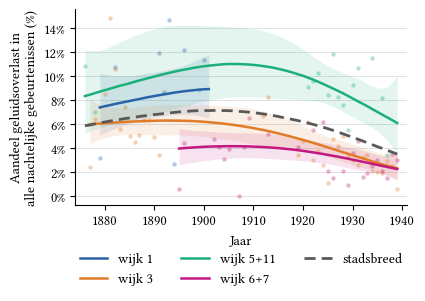

In [29]:
KLEUREN = KLEUR_WIJK
LABELS = {5: "wijk 5+11", 6: "wijk 6+7"}
MIN_N = 100

fig, ax = plt.subplots()

for wijk in sorted(resultaten):
    kleur = KLEUREN[wijk]
    r = resultaten[wijk]

    zicht = agg[(agg["district"] == wijk) & (agg["n"] >= MIN_N)]
    ax.scatter(zicht["year"], zicht["k"] / zicht["n"] * 100,
               s=10, color=kleur, alpha=0.35, linewidth=0, zorder=2)

    ax.fill_between(r["jaren"], r["lo"], r["hi"],
                    color=kleur, alpha=0.12, linewidth=0, zorder=1)

    ax.plot(r["jaren"], r["med"], color=kleur, linewidth=1.8, zorder=3,
            label=LABELS.get(wijk, f"wijk {wijk}"))

ax.plot(stadsbreed["jaren"], stadsbreed["med"],
        color="0.35", linewidth=2, linestyle=(0, (4, 2.2)), zorder=4,
        label="stadsbreed")

ax.set_xlabel("Jaar")
ax.set_ylabel("Aandeel geluidsoverlast in\nalle nachtelijke gebeurtenissen (%)")
ax.yaxis.set_major_formatter(
    plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.0f}%")
)

ax.set_xlim(1874, 1941)
ax.yaxis.set_major_locator(plt.matplotlib.ticker.MultipleLocator(2))  # gehele procenten

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18),
          ncol=3, frameon=False)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y")

plt.tight_layout()
plt.subplots_adjust(bottom=0.25)

pas_breedte_aan(fig, tight=True)
fig.savefig("../../fig/H8/8.8_geluidsoverlast_per_wijk.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [30]:
n_5, N_5 = int(agg["k"].sum()), int(agg["n"].sum())
print(f"Afbeelding 7: n={nl(n_5)} / N={nl(N_5)} ({n_5/N_5*100:.1f}%)")
print(f"{agg['year'].min()}-{agg['year'].max()}, {agg['year'].nunique()} jaren, "
      f"{agg['district'].nunique()} wijken")

Afbeelding 7: n=1.592 / N=29.867 (5.3%)
1876-1939, 56 jaren, 4 wijken


In [31]:
# waar ligt de top van de stadsbrede curve?
top = stadsbreed["jaren"][np.argmax(stadsbreed["med"])]
print("top:", top, f"{stadsbreed['med'].max():.1f}%")

for j in (1876, 1890, 1905, 1920, 1939):
    i = list(stadsbreed["jaren"]).index(j)
    print(f"{j}: {stadsbreed['med'][i]:.1f}% "
          f"[{stadsbreed['lo'][i]:.1f}-{stadsbreed['hi'][i]:.1f}]")

top: 1902 7.1%
1876: 5.9% [1.9-16.0]
1890: 6.8% [2.6-17.3]
1905: 7.1% [3.0-17.8]
1920: 6.2% [2.4-17.4]
1939: 3.5% [1.1-13.3]


In [32]:
jaren = stadsbreed["jaren"]
wijk = agg["district"].cat.categories[0]
pred = model_g.predict(idata_g, data=_grid(jaren, wijk),
                       kind="response_params", inplace=False,
                       include_group_specific=False)
naam = "p" if "p" in pred.posterior else "mu"
p = pred.posterior[naam] * 100

def contrast(a, b):
    ia, ib = list(jaren).index(a), list(jaren).index(b)
    d = (p.isel(__obs__=ib) - p.isel(__obs__=ia)).values.flatten()
    lo, hi = np.percentile(d, [3, 97])
    print(f"{a}->{b}: {d.mean():+.1f} pp [{lo:+.1f}, {hi:+.1f}]  "
          f"P(daling)={np.mean(d < 0):.2f}")

contrast(1876, 1905)
contrast(1905, 1939)
contrast(1890, 1939)

1876->1905: +1.3 pp [-3.1, +6.2]  P(daling)=0.23
1905->1939: -3.6 pp [-9.2, +0.6]  P(daling)=0.96
1890->1939: -3.1 pp [-9.6, +3.0]  P(daling)=0.91


In [33]:
pad = "../../data/H8/Gemeenteblad_PV_MDK.xlsx"

raw = pd.read_excel(pad, header=None)

print(raw.shape)
display(raw.head())
display(raw.tail())

(10, 73)


,0,1,2,3,4,5,6,7,8,9,...,63,64,65,66,67,68,69,70,71,72
0,Jaar,1842.0,1843.0,1844.0,1845.0,1846.0,1847.0,1848.0,1849.0,1850.0,...,1904,1905,1906,1907,1908,1909,1910,1911,1912,1913
1,Nachtlawaai,48.0,65.0,39.0,64.0,38.0,42.0,44.0,60.0,96.0,...,1337,1192,1179,1073,946,981,829,1062,955,783
2,Openbare orde,470.0,475.0,359.0,434.0,599.0,550.0,651.0,552.0,529.0,...,7448,7954,8014,7714,6166,7326,7340,6910,6942,8616
3,Sekswerk,1.0,5.0,2.0,0.0,2.0,0.0,0.0,3.0,1.0,...,1326,1479,1656,1624,657,1697,1489,1622,1127,2582
4,Sluiting herbergen en cabarets,96.0,123.0,75.0,111.0,205.0,194.0,188.0,134.0,190.0,...,420,395,475,428,374,371,253,51,129,259


,0,1,2,3,4,5,6,7,8,9,...,63,64,65,66,67,68,69,70,71,72
5,Dansen zonder toelating,6.0,8.0,4.0,4.0,36.0,5.0,3.0,28.0,7.0,...,92,168,193,160,164,148,112,66,65,161
6,Orgelspel op straat zonder toelating,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,28,39,68,19,23,43,15,24,22,11
7,Nachtelijke aanranding op straat,NaN,NaN,NaN,NaN,NaN,42.0,44.0,NaN,NaN,...,15,30,47,40,20,21,40,51,19,98
8,Totaalpvs,1527.0,1586.0,1529.0,1948.0,2183.0,2443.0,2247.0,2773.0,2599.0,...,29368,27930,27933,26902,22912,27295,26292,25604,26382,33779
9,Bevolking,78150.0,78618.0,79737.0,81187.0,82442.0,85818.0,87025.0,86994.0,89377.0,...,301647,304975,304032,310903,314135,317171,308618,312884,313833,318199


In [34]:
jaren = pd.to_numeric(raw.iloc[0, 1:], errors="coerce")

nachtlawaai = pd.to_numeric(
    raw.loc[raw[0] == "Nachtlawaai"].iloc[0, 1:],
    errors="coerce"
)

totaal_pvs = pd.to_numeric(
    raw.loc[raw[0] == "Totaalpvs"].iloc[0, 1:],
    errors="coerce"
)

bevolking = pd.to_numeric(
    raw.loc[raw[0] == "Bevolking"].iloc[0, 1:],
    errors="coerce"
)

d_pv = pd.DataFrame({
    "year": jaren.values,
    "nachtlawaai": nachtlawaai.values,
    "totaal_pvs": totaal_pvs.values,
    "bevolking": bevolking.values
})


In [35]:
d_pv = d_pv[
    (d_pv["year"] >= 1876) &
    d_pv["nachtlawaai"].notna() &
    d_pv["bevolking"].notna()
].copy()

d_pv["year"] = d_pv["year"].astype(int)

display(d_pv)

,year,nachtlawaai,totaal_pvs,bevolking
34,1876,257.0,6573.0,162547.0
35,1877,272.0,6841.0,166144.0
36,1878,295.0,6800.0,169981.0
37,1879,281.0,9862.0,173643.0
38,1880,315.0,9506.0,179034.0
39,1881,258.0,9468.0,185480.0
40,1882,204.0,11644.0,190665.0
41,1883,309.0,11117.0,195812.0
42,1884,397.0,12113.0,201429.0
43,1885,407.0,13318.0,207907.0


In [36]:
d_pv["nachtlawaai_per_10000"] = (
    d_pv["nachtlawaai"] / d_pv["bevolking"] * 10_000
)

d_pv["aandeel_nachtlawaai_pv"] = (
    d_pv["nachtlawaai"] / d_pv["totaal_pvs"] * 100
)

display(
    d_pv[[
        "year",
        "nachtlawaai",
        "bevolking",
        "nachtlawaai_per_10000",
        "aandeel_nachtlawaai_pv"
    ]]
)

,year,nachtlawaai,bevolking,nachtlawaai_per_10000,aandeel_nachtlawaai_pv
34,1876,257.0,162547.0,15.810812,3.909935
35,1877,272.0,166144.0,16.371341,3.976027
36,1878,295.0,169981.0,17.354881,4.338235
37,1879,281.0,173643.0,16.182628,2.849321
38,1880,315.0,179034.0,17.594423,3.313697
39,1881,258.0,185480.0,13.909856,2.724968
40,1882,204.0,190665.0,10.699394,1.751975
41,1883,309.0,195812.0,15.780442,2.779527
42,1884,397.0,201429.0,19.709178,3.277470
43,1885,407.0,207907.0,19.576060,3.056014


In [37]:
d_model = d_pv[
    ["year", "nachtlawaai", "bevolking"]
].dropna().copy()

d_model["k"] = d_model["nachtlawaai"].astype(int)

d_model["log_bev"] = np.log(d_model["bevolking"] / 10_000)

jaar_gem = d_model["year"].mean()
d_model["year_c"] = d_model["year"] - jaar_gem

model_pv = bmb.Model(
    "k ~ bs(year_c, df=4) + offset(log_bev)",
    d_model,
    family="negativebinomial"
)

In [38]:
idata_pv = model_pv.fit(
    draws=2000,
    tune=2000,
    chains=4,
    target_accept=0.95,
    random_seed=42
)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, Intercept, bs(year_c, df=4)]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 8 seconds.


In [39]:
print(
    "Divergences:",
    idata_pv.sample_stats["diverging"].sum().item()
)

display(az.summary(idata_pv))

Divergences: 0


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,31.606,8.398,17.236,47.710,0.111,0.080,5724.0,5397.0,1.0
Intercept,2.746,0.131,2.502,2.995,0.002,0.001,5704.0,5411.0,1.0
"bs(year_c, df=4)[0]",-0.010,0.274,-0.514,0.521,0.004,0.003,5103.0,4695.0,1.0
"bs(year_c, df=4)[1]",0.991,0.234,0.529,1.408,0.003,0.002,5587.0,5141.0,1.0
"bs(year_c, df=4)[2]",1.005,0.243,0.552,1.468,0.003,0.002,5138.0,5002.0,1.0
"bs(year_c, df=4)[3]",0.505,0.173,0.184,0.836,0.002,0.002,6159.0,4929.0,1.0


In [40]:
jaren_pred = np.arange(
    d_model["year"].min(),
    d_model["year"].max() + 1
)

nieuw_pv = pd.DataFrame({
    "year": jaren_pred,
    "year_c": jaren_pred - jaar_gem,
    "log_bev": 0.0   # log(10.000 / 10.000) = 0
})

model_pv.predict(
    idata_pv,
    data=nieuw_pv,
    kind="response_params"
)

mu_pv = idata_pv.posterior["mu"]

gem_pv = mu_pv.mean(("chain", "draw")).values

h94_pv = az.hdi(
    mu_pv,
    hdi_prob=0.94
)["mu"].values

h50_pv = az.hdi(
    mu_pv,
    hdi_prob=0.50
)["mu"].values

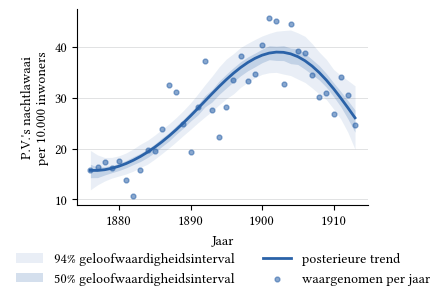

In [41]:
fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.66))

ax.fill_between(
    jaren_pred,
    h94_pv[:, 0],
    h94_pv[:, 1],
    color=NACHT,
    alpha=.10,
    lw=0,
    label="94% geloofwaardigheidsinterval"
)

ax.fill_between(
    jaren_pred,
    h50_pv[:, 0],
    h50_pv[:, 1],
    color=NACHT,
    alpha=.20,
    lw=0,
    label="50% geloofwaardigheidsinterval"
)

ax.plot(
    jaren_pred,
    gem_pv,
    color=NACHT,
    lw=2,
    label="posterieure trend"
)

ax.scatter(
    d_pv["year"],
    d_pv["nachtlawaai_per_10000"],
    color=NACHT,
    s=12,
    alpha=.55,
    zorder=3,
    label="waargenomen per jaar"
)

ax.set_xlabel("Jaar")
ax.set_ylabel(
    "P.V.'s nachtlawaai\n"
    "per 10.000 inwoners"
)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y")

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False
)

plt.tight_layout()
plt.subplots_adjust(bottom=.25)
plt.show()

In [42]:
d_aandeel = d_pv[
    ["year", "nachtlawaai", "totaal_pvs"]
].dropna().copy()

d_aandeel["k"] = d_aandeel["nachtlawaai"].astype(int)
d_aandeel["n"] = d_aandeel["totaal_pvs"].astype(int)

jaar_gem_aandeel = d_aandeel["year"].mean()
d_aandeel["year_c"] = d_aandeel["year"] - jaar_gem_aandeel

model_aandeel = bmb.Model(
    "p(k, n) ~ bs(year_c, df=4)",
    d_aandeel,
    family="beta_binomial"
)

In [43]:
idata_aandeel = model_aandeel.fit(
    draws=2000,
    tune=2000,
    chains=4,
    target_accept=0.95,
    random_seed=42
)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [kappa, Intercept, bs(year_c, df=4)]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 7 seconds.


In [44]:

print(
    "Divergences:",
    idata_aandeel.sample_stats["diverging"].sum().item()
)

display(az.summary(idata_aandeel))

Divergences: 0


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
kappa,1186.200,321.363,618.104,1778.683,4.433,3.225,5382.0,5367.0,1.0
Intercept,-3.170,0.119,-3.395,-2.951,0.002,0.001,4529.0,4419.0,1.0
"bs(year_c, df=4)[0]",-0.509,0.249,-0.974,-0.034,0.004,0.003,4497.0,4915.0,1.0
"bs(year_c, df=4)[1]",-0.236,0.203,-0.634,0.131,0.003,0.002,5719.0,4905.0,1.0
"bs(year_c, df=4)[2]",0.326,0.212,-0.081,0.716,0.003,0.002,4717.0,4616.0,1.0
"bs(year_c, df=4)[3]",-0.372,0.156,-0.663,-0.077,0.002,0.002,5215.0,4859.0,1.0


In [45]:
# Voorspellingen aandeel nachtlawaai in alle PV's
jaren_aandeel = np.arange(
    d_aandeel["year"].min(),
    d_aandeel["year"].max() + 1
)

nieuw_aandeel = pd.DataFrame({
    "year": jaren_aandeel,
    "year_c": jaren_aandeel - jaar_gem_aandeel
})

model_aandeel.predict(
    idata_aandeel,
    data=nieuw_aandeel,
    kind="response_params"
)

# Omzetten naar procent
p_aandeel = idata_aandeel.posterior["mu"] * 100

gem_aandeel = p_aandeel.mean(("chain", "draw")).values
h94_aandeel = az.hdi(p_aandeel, hdi_prob=.94)["mu"].values
h50_aandeel = az.hdi(p_aandeel, hdi_prob=.50)["mu"].values

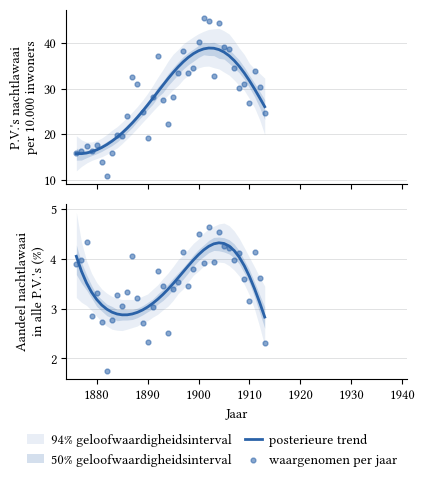

In [46]:
plt.rcParams.update({
    'font.family': 'Libertinus Serif',
    'font.size': CORPS,
    'axes.titlesize': CORPS,
    'axes.labelsize': CORPS,
    'xtick.labelsize': CORPS,
    'ytick.labelsize': CORPS,
    'legend.fontsize': CORPS,
})

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 1.15),
    sharex=True
)

ax1.fill_between(
    jaren_pred,
    h94_pv[:, 0],
    h94_pv[:, 1],
    color=NACHT,
    alpha=.10,
    lw=0
)

ax1.fill_between(
    jaren_pred,
    h50_pv[:, 0],
    h50_pv[:, 1],
    color=NACHT,
    alpha=.20,
    lw=0
)

ax1.plot(
    jaren_pred,
    gem_pv,
    color=NACHT,
    lw=2
)

ax1.scatter(
    d_pv["year"],
    d_pv["nachtlawaai_per_10000"],
    color=NACHT,
    s=12,
    alpha=.55,
    zorder=3
)

ax1.set_ylabel(
    "P.V.'s nachtlawaai\n"
    "per 10.000 inwoners"
)


ax2.fill_between(
    jaren_aandeel,
    h94_aandeel[:, 0],
    h94_aandeel[:, 1],
    color=NACHT,
    alpha=.10,
    lw=0,
    label="94% geloofwaardigheidsinterval"
)

ax2.fill_between(
    jaren_aandeel,
    h50_aandeel[:, 0],
    h50_aandeel[:, 1],
    color=NACHT,
    alpha=.20,
    lw=0,
    label="50% geloofwaardigheidsinterval"
)

ax2.plot(
    jaren_aandeel,
    gem_aandeel,
    color=NACHT,
    lw=2,
    label="posterieure trend"
)

ax2.scatter(
    d_pv["year"],
    d_pv["aandeel_nachtlawaai_pv"],
    color=NACHT,
    s=12,
    alpha=.55,
    zorder=3,
    label="waargenomen per jaar"
)

ax2.set_ylabel(
    "Aandeel nachtlawaai\nin alle P.V.'s (%)"
)

ax2.set_xlabel("Jaar")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y")

ax2.set_xlim(1874, 1941)


handles, labels = ax2.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.01),
    handlelength=1.2,
    columnspacing=1.0,
    handletextpad=0.5
)

plt.tight_layout(rect=[0, .10, 1, 1])

pas_breedte_aan(fig, tight=True)
fig.savefig(
    "../../fig/H8/8.9_nachtlawaai_PVs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
print(raw.head())

                               0       1       2       3       4       5   \
0                            Jaar  1842.0  1843.0  1844.0  1845.0  1846.0   
1                     Nachtlawaai    48.0    65.0    39.0    64.0    38.0   
2                   Openbare orde   470.0   475.0   359.0   434.0   599.0   
3                        Sekswerk     1.0     5.0     2.0     0.0     2.0   
4  Sluiting herbergen en cabarets    96.0   123.0    75.0   111.0   205.0   

       6       7       8       9   ...    63    64    65    66    67    68  \
0  1847.0  1848.0  1849.0  1850.0  ...  1904  1905  1906  1907  1908  1909   
1    42.0    44.0    60.0    96.0  ...  1337  1192  1179  1073   946   981   
2   550.0   651.0   552.0   529.0  ...  7448  7954  8014  7714  6166  7326   
3     0.0     0.0     3.0     1.0  ...  1326  1479  1656  1624   657  1697   
4   194.0   188.0   134.0   190.0  ...   420   395   475   428   374   371   

     69    70    71    72  
0  1910  1911  1912  1913  
1   829  106

In [48]:
pv = raw.set_index(0).T
pv = pv.rename(columns={"Jaar": "year"})
pv["year"] = pv["year"].astype(int)

print(pv.columns.tolist())
print(f"{pv['year'].min()}-{pv['year'].max()}, {len(pv)} jaren")

['year', 'Nachtlawaai', 'Openbare orde', 'Sekswerk', 'Sluiting herbergen en cabarets', 'Dansen zonder toelating', 'Orgelspel op straat zonder toelating', 'Nachtelijke aanranding op straat', 'Totaalpvs', 'Bevolking']
1842-1913, 72 jaren


In [49]:
pv_h4 = pv[pv["year"].between(1876, 1913)].copy()

n = int(pv_h4["Nachtlawaai"].sum())
N = int(pv_h4["Totaalpvs"].sum())

print(f"Afbeelding 7, boven: n={nl(n)} P.V.'s, {len(pv_h4)} jaren, "
      f"{pv_h4['year'].min()}-{pv_h4['year'].max()}")
print(f"Afbeelding 7, onder: n={nl(n)} / N={nl(N)} ({n/N*100:.1f}%)")

# controle op hiaten
ontbreekt = set(range(1876, 1914)) - set(pv_h4["year"])
print("ontbrekende jaren:", sorted(ontbreekt) or "geen")

Afbeelding 7, boven: n=28.690 P.V.'s, 38 jaren, 1876-1913
Afbeelding 7, onder: n=28.690 / N=799.109 (3.6%)
ontbrekende jaren: geen


In [50]:
p_prob = idata_spline.posterior["mu"]

# helling per jaar, in procentpunten
delta = (p_prob.diff(dim="__obs__") * 100).stack(s=("chain", "draw"))
voor_wo1 = delta.isel(__obs__=slice(0, 38))          # 1877-1914
print("gem. jaarlijkse verandering 1877-1914:",
      float(voor_wo1.mean()).__round__(3), "pp")
print("94%-interval:", np.quantile(voor_wo1.values, [0.03, 0.97]).round(3))

# netto verschil tussen begin en eind van de vooroorlogse reeks
netto = (p_prob.isel(__obs__=38) - p_prob.isel(__obs__=1)) * 100
print("\nnetto 1877 -> 1914:", float(netto.mean()).__round__(2), "pp",
      np.quantile(netto.stack(s=("chain", "draw")).values, [0.03, 0.97]).round(2))

gem. jaarlijkse verandering 1877-1914: -0.018 pp
94%-interval: [-0.226  0.308]

netto 1877 -> 1914: -0.84 pp [-3.51  1.54]
